# 01 — Pipeline de razonamiento, búsqueda y resultados
**Caso C: sueño infantil**. Los estados representan avances en el proceso de registro y análisis, no diagnósticos clínicos.

## Problema y espacio de estados
- Estado: tupla `(edad, sueno, validado, orientacion)` de indicadores 0/1.
- Inicial: `(0,0,0,0)`. Meta: `(1,1,1,1)`.
- Restricciones: validar requiere edad y sueño; orientar requiere datos validados.
- Algoritmo: BFS, búsqueda en anchura, con costo unitario por operación.

In [1]:
from collections import deque
import matplotlib.pyplot as plt
from pprint import pprint

estado_inicial=(0,0,0,0)
meta=(1,1,1,1)

def sucesores(s):
    edad,sueno,validado,orientacion=s
    resultados=[]
    if not edad: resultados.append(("registrar_edad",(1,sueno,validado,orientacion)))
    if not sueno: resultados.append(("registrar_sueno",(edad,1,validado,orientacion)))
    if edad and sueno and not validado: resultados.append(("validar_variables",(edad,sueno,1,orientacion)))
    if validado and not orientacion: resultados.append(("documentar_orientacion",(edad,sueno,validado,1)))
    return resultados

def bfs(inicio,objetivo):
    cola=deque([(inicio,[])]); vistos={inicio}; orden=[]
    while cola:
        actual,ruta=cola.popleft();orden.append(actual)
        if actual==objetivo: return ruta,orden
        for accion,siguiente in sucesores(actual):
            if siguiente not in vistos:
                vistos.add(siguiente);cola.append((siguiente,ruta+[(accion,siguiente)]))
    return None,orden

ruta,orden=bfs(estado_inicial,meta)
print("Problema: documentar registro completo y validado del sueño infantil")
print("Estado inicial:",estado_inicial,"| Estado objetivo:",meta)
print("Estados explorados:",len(orden))
print("Resultado:","META ALCANZADA" if ruta is not None else "SIN SOLUCION")
for paso,(accion,estado) in enumerate(ruta,1):print(f"Paso {paso}: {accion} -> {estado}")
assert len(ruta)==4


Problema: documentar registro completo y validado del sueño infantil
Estado inicial: (0, 0, 0, 0) | Estado objetivo: (1, 1, 1, 1)
Estados explorados: 6
Resultado: META ALCANZADA
Paso 1: registrar_edad -> (1, 0, 0, 0)
Paso 2: registrar_sueno -> (1, 1, 0, 0)
Paso 3: validar_variables -> (1, 1, 1, 0)
Paso 4: documentar_orientacion -> (1, 1, 1, 1)


## Visualización de la búsqueda
El gráfico muestra los estados examinados por BFS, incluido el estado objetivo.

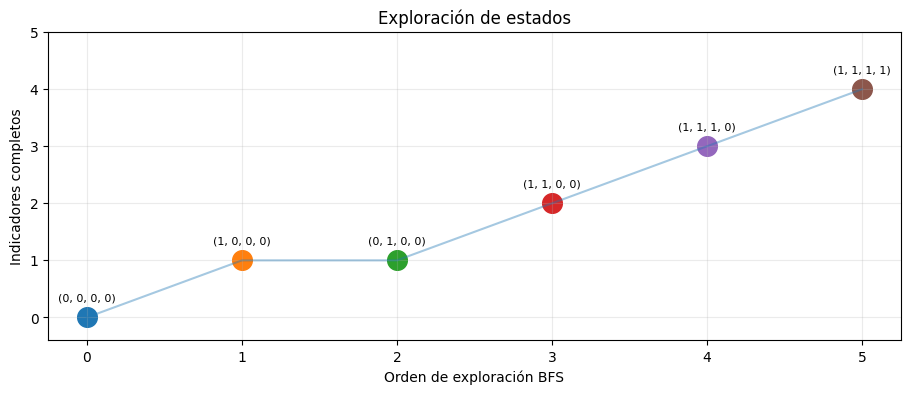

In [2]:
fig,ax=plt.subplots(figsize=(11,4))
for i,s in enumerate(orden):
    ax.scatter(i,sum(s),s=200)
    ax.annotate(str(s),(i,sum(s)),xytext=(0,12),textcoords="offset points",ha="center",fontsize=8)
ax.plot(range(len(orden)),[sum(s) for s in orden],alpha=.4)
ax.set(xlabel="Orden de exploración BFS",ylabel="Indicadores completos",title="Exploración de estados")
ax.set_xticks(range(len(orden)));ax.set_ylim(-.4,5);ax.grid(alpha=.25);plt.show()

## Conclusión
BFS alcanza la meta en **cuatro operaciones**; dado que cada operador agrega un único indicador, ningún camino puede requerir menos de cuatro operaciones. La solución solo representa un proceso de registro, no una recomendación médica.